# 1. 第一次运行：示踪剂扩散

**目标。** 在不涉及化学的情况下完整运行一次代码。你将：

- 写出含四节的完整 `case.yaml`，
- 用 `coupling.py` 运行它，
- 找到结果文件，
- 用解析解检查结果。

`coupling.mode: diffusion` 会关闭 GEMS，只运行 `transport.py` 和 `output.py`。所以这个算例也能检查 FEniCSx 是否装好了。

| | |
|---|---|
| 模式 | `diffusion` |
| 区域 | 一维，10 mm，50 个单元 |
| 物理 | $\phi\,\partial c/\partial t = \partial_x (D_e\,\partial_x c)$ |
| 运行时间 | 约 2 s |

## 文件夹结构

本 notebook 放在 `FEniCSx_GEMS` 文件夹旁边，每篇教程的算例放在自己的文件夹中：

```text
FEniCSx_GEMS/          四个模块 + chemistry_data/
t01_tracer/case.yaml   下面写出
t01_tracer/results/    运行时创建
```

## 写输入文件

`case.yaml` 始终是同样的四节，每节对应一个 Python 模块。diffusion 模式只读取 `transport`、`coupling` 和 `output`；`chemistry` 必须存在，但不使用。

下面单元格中的 `%%writefile` 会把内容写进文件。在 notebook 之外，直接用文本编辑器修改 `case.yaml` 即可。

In [1]:
import os
os.makedirs('t01_tracer', exist_ok=True)

In [2]:
%%writefile t01_tracer/case.yaml
# Tutorial 1: one tracer diffusing through a porous column, no chemistry.

chemistry:                       # not used in diffusion mode, but the section must exist
  project: ../../FEniCSx_GEMS/chemistry_data/b_time0-dat.lst
  temperature: 298.15
  pressure: 100000
  aqueous_phase: aq_gen
  solid_phases: []
  gibbs: {}
  initial: {}

transport:
  geometry:
    length: 0.01                 # m
    cells: 50                    # uniform 1D mesh, dx = 0.2 mm
  material:
    phi: 0.4                     # porosity
    De: 4.0e-10                  # effective diffusion coefficient, m2/s
  components: [tracer]           # names of the transported tracers
  initial: {tracer: 0.0}         # mol/m3 pore water
  boundary:
    left:
      type: dirichlet
      concentrations: {tracer: 1.0}
    right:
      type: dirichlet
      concentrations: {tracer: 0.0}
  solver:
    ksp_type: preonly
    pc_type: lu
    rtol: 1.0e-10
    max_iterations: 1000

coupling:
  mode: diffusion                # diffusion | chemistry | coupled
  time:
    dt: 100                      # s
    end: 20000                   # s
  update_porosity: false         # must be false without chemistry
  update_diffusivity: false
  exponent: 1.0                  # unused here

output:
  folder: results                # relative to this case.yaml
  every: 50                      # write profiles every 50 steps (5000 s)

Overwriting t01_tracer/case.yaml


## 运行

在终端中就是 `python FEniCSx_GEMS/coupling.py t01_tracer/case.yaml`（Windows 上双击 `Run.cmd`，它调用 WSL 中的 Python）。`!` 在 notebook 中运行同一条命令。

In [3]:
!python ../FEniCSx_GEMS/coupling.py t01_tracer/case.yaml

step=0, time=0 s, balance=0.000e+00 mol/m2, chemistry=0.000e+00 mol/m3, water mismatch=0.00%
step=50, time=5000 s, balance=6.505e-18 mol/m2, chemistry=0.000e+00 mol/m3, water mismatch=0.00%


step=100, time=10000 s, balance=1.691e-17 mol/m2, chemistry=0.000e+00 mol/m3, water mismatch=0.00%
step=150, time=15000 s, balance=2.992e-17 mol/m2, chemistry=0.000e+00 mol/m3, water mismatch=0.00%


step=200, time=20000 s, balance=4.380e-17 mol/m2, chemistry=0.000e+00 mol/m3, water mismatch=0.00%


Saved: t01_tracer/results


## 运行写出了什么

所有文件都写入 `output.folder`。`summary.txt` 说明运行是 COMPLETED 还是 FAILED，并列出最大的守恒误差。

In [4]:
print(sorted(os.listdir('t01_tracer/results')))
print(open('t01_tracer/results/summary.txt').read())

['case_used.json', 'fields.h5', 'fields.xdmf', 'mass_balance.csv', 'profiles.csv', 'profiles.png', 'simulation.log', 'summary.txt']
COMPLETED
Mode: diffusion
Cells/states: 50; reference length: 0.01 m
Scheme: backward Euler, DG0 two-point cell flux (transport modes only)
Linear solver: preonly / lu
Final time: 20000.0 s; steps: 200
Amounts: mol/m3 bulk; concentrations: mol/m3 pore water
Inventory and boundary exchange: mol/m2 (unit cross-sectional area)
Maximum balance error: 4.380177e-17 mol/m2
Maximum chemical element reconstruction error: 0.000000e+00 mol/m3
Maximum aqueous-volume/porosity mismatch: 0.000000%
GEMS initialisation: independent cold start for every equilibrium call
Final porosity range: 0.4 to 0.4
Final De range: 4e-10 to 4e-10 m2/s
Porosity feedback: False
Diffusivity feedback: False
Limit: numerical demonstration, not experimental validation.
Limit: saturated pore volume is assumed; aqueous volume mismatch is diagnostic only.



## 与解析解比较

当 $\phi$ 和 $D_e$ 不变时，方程就是普通扩散，孔隙扩散系数 $D = D_e/\phi = 10^{-9}$ m²/s。对 $c(0,t)=1$、$c(L,t)=0$、$c(x,0)=0$：

$$
c(x,t) = 1-\frac{x}{L}-\frac{2}{\pi}\sum_{n=1}^{\infty}\frac{1}{n}\sin\frac{n\pi x}{L}\,
\exp\!\left(-\frac{n^2\pi^2 D t}{L^2}\right)
$$

`profiles.csv` 中每个单元、每个保存时刻一行。示踪剂浓度在 `tracer_c_mol_m3_water` 列（mol/m³ 孔隙水）；`tracer_total_mol_m3_bulk` 是同一量按体相体积计。

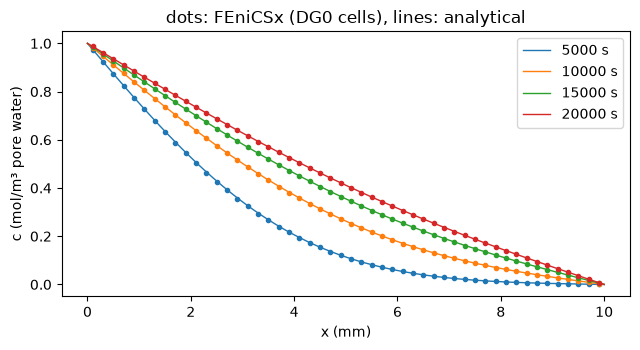

max |error| at t = 20000 s: 9.33e-04 mol/m3


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

p = pd.read_csv('t01_tracer/results/profiles.csv')
L, D = 0.01, 4.0e-10 / 0.4

def exact(x, t, terms=400):
    n = np.arange(1, terms + 1)[:, None]
    return 1 - x / L - 2 / np.pi * np.sum(np.sin(n * np.pi * x / L) / n * np.exp(-(n * np.pi) ** 2 * D * t / L ** 2), axis=0)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
xf = np.linspace(0, L, 400)
for t, g in p[p.time_s > 0].groupby('time_s'):
    line, = ax.plot(g.x_m * 1e3, g.tracer_c_mol_m3_water, 'o', ms=3)
    ax.plot(xf * 1e3, exact(xf, t), '-', color=line.get_color(), lw=1, label=f'{t:.0f} s')
ax.set_xlabel('x (mm)'); ax.set_ylabel('c (mol/m³ pore water)')
ax.set_title('dots: FEniCSx (DG0 cells), lines: analytical')
ax.legend(); plt.tight_layout(); plt.show()

last = p[p.time_s == p.time_s.max()]
err = np.max(np.abs(last.tracer_c_mol_m3_water - exact(last.x_m.values, last.time_s.values[0])))
print(f'max |error| at t = {last.time_s.values[0]:.0f} s: {err:.2e} mol/m3')

误差约为 $10^{-3}$，来自时间上一阶的向后欧拉和以单元中心存值的网格。把 `dt` 减半或把 `cells` 加倍，误差就会下降。

## 质量守恒

代码每一步都检查：柱中的量只因穿过边界的量而变化。`mass_balance.csv` 中有存量（每 m² 截面的 mol）、累计边界输入以及两者之差。

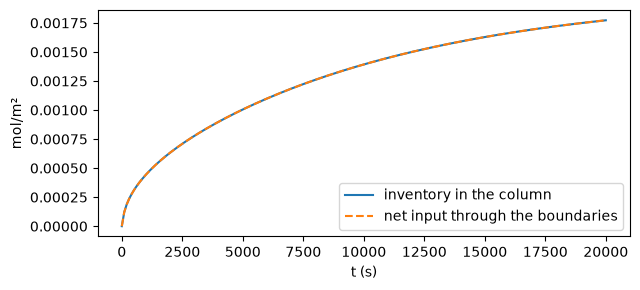

largest balance error: 4.380176776841438e-17 mol/m2


In [6]:
m = pd.read_csv('t01_tracer/results/mass_balance.csv')
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.plot(m.time_s, m.inventory_mol_m2, label='inventory in the column')
ax.plot(m.time_s, m.cumulative_net_in_mol_m2, '--', label='net input through the boundaries')
ax.set_xlabel('t (s)'); ax.set_ylabel('mol/m²'); ax.legend(); plt.tight_layout(); plt.show()
print('largest balance error:', abs(m.balance_error_mol_m2).max(), 'mol/m2')

## 改一处：封闭右端

输入只在 `case.yaml` 中修改。这里载入文件，把右边界改为封闭（`no_flux`），把结果写到另一个文件夹，再运行一次。在文本编辑器中只需改两行：

```yaml
    right:
      type: no_flux
...
output:
  folder: results_noflux
```

In [7]:
import yaml
case = yaml.safe_load(open('t01_tracer/case.yaml'))
case['transport']['boundary']['right']['type'] = 'no_flux'
case['coupling']['time']['end'] = 100000
case['output']['folder'] = 'results_noflux'
yaml.safe_dump(case, open('t01_tracer/case_noflux.yaml', 'w'), sort_keys=False)
!python ../FEniCSx_GEMS/coupling.py t01_tracer/case_noflux.yaml > /dev/null && tail -n 1 t01_tracer/results_noflux/simulation.log

Limit: saturated pore volume is assumed; aqueous volume mismatch is diagnostic only.


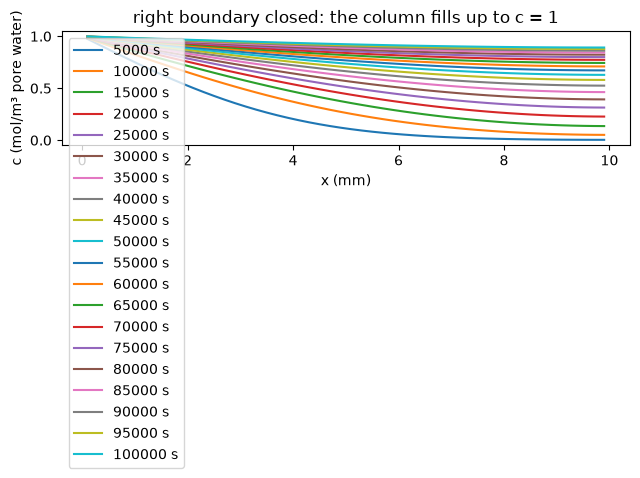

In [8]:
q = pd.read_csv('t01_tracer/results_noflux/profiles.csv')
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for t, g in q[q.time_s > 0].groupby('time_s'):
    ax.plot(g.x_m * 1e3, g.tracer_c_mol_m3_water, label=f'{t:.0f} s')
ax.set_xlabel('x (mm)'); ax.set_ylabel('c (mol/m³ pore water)')
ax.set_title('right boundary closed: the column fills up to c = 1')
ax.legend(); plt.tight_layout(); plt.show()

**下一篇：** [教程 2](02_single_equilibrium.ipynb) 打开 GEMS，计算一次化学平衡。